# Практическое занятие №1. Прогнозирование оттока клиентов телеком-оператора

**Датасет:** Telco Customer Churn (IBM), взят из репозитория [plotly/datasets](https://github.com/plotly/datasets).

**Задача:** по данным о клиенте (услуги, тип договора, способ оплаты, сколько платит и т.д.) предсказать, уйдёт он от оператора или нет (столбец `Churn`). Это задача бинарной классификации.

План работы:
1. Загрузка данных и разведочный анализ (EDA)
2. Предобработка
3. Обучение базовой модели (логистическая регрессия)
4. Оценка качества
5. Дополнительно: Random Forest, сравнение моделей и важность признаков

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, roc_curve, f1_score)

import os
os.makedirs('images', exist_ok=True)  # сюда сохраняю графики для отчёта

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 50)
RANDOM_STATE = 42

## Этап 1. Загрузка и разведка данных (EDA)

### 1. Загрузка датасета

In [2]:
url = 'https://raw.githubusercontent.com/plotly/datasets/master/telco-customer-churn-by-IBM.csv'
df = pd.read_csv(url)
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### 2. Размерность, типы данных и пропуски

In [3]:
print('Размерность таблицы:', df.shape)
print(f'Строк (клиентов): {df.shape[0]}, столбцов: {df.shape[1]}')

Размерность таблицы: (7043, 21)
Строк (клиентов): 7043, столбцов: 21


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
print('Количество пропусков по столбцам:')
print(df.isnull().sum())

Количество пропусков по столбцам:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64



### 3. Пустые значения в столбце TotalCharges

In [6]:
# ищем значения, которые не превращаются в число
bad_mask = pd.to_numeric(df['TotalCharges'], errors='coerce').isna()
print('Нечисловых значений в TotalCharges:', bad_mask.sum())
df.loc[bad_mask, ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges']]

Нечисловых значений в TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


In [ ]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].str.strip(), errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(0).astype('float64')

Пропусков после конвертации: 11
Тип столбца: float64
Пропусков после заполнения: 0


In [8]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304
std,0.368612,24.559481,30.090047,2266.794470
min,0.000000,0.000000,18.250000,0.000000
25%,0.000000,9.000000,35.500000,398.550000
50%,0.000000,29.000000,70.350000,1394.550000
75%,0.000000,55.000000,89.850000,3786.600000
max,1.000000,72.000000,118.750000,8684.800000


### 4. Распределение целевой переменной Churn

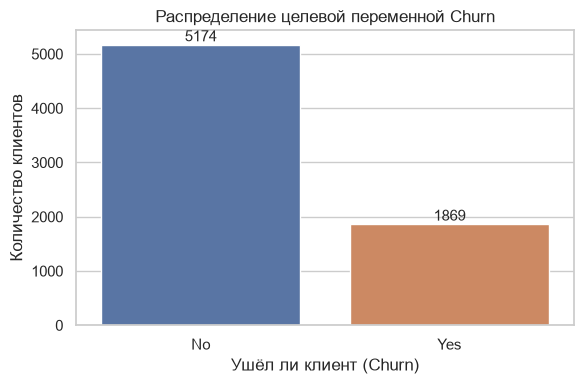

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x='Churn', hue='Churn', palette=['#4C72B0', '#DD8452'], legend=False, ax=ax)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom', fontsize=11)
ax.set_title('Распределение целевой переменной Churn')
ax.set_xlabel('Ушёл ли клиент (Churn)')
ax.set_ylabel('Количество клиентов')
plt.tight_layout()
plt.savefig('images/churn_countplot.png', dpi=150)
plt.show()

print(df['Churn'].value_counts())
print()
print((df['Churn'].value_counts(normalize=True) * 100).round(2))

**Вывод:** да, дисбаланс классов есть. Ушедших клиентов примерно 26.5%, оставшихся — 73.5%, то есть соотношение примерно 1 к 3. Это неплохо, но из-за него нельзя ориентироваться только на accuracy: модель, которая всегда отвечает «No», уже получит ~73% точности и при этом будет бесполезна. Поэтому дальше надо смотреть в первую очередь на Recall/F1 по классу «Yes» и на ROC-AUC. Также при разбиении на train/test надо использовать стратификацию, чтобы доля ушедших в обеих частях была одинаковой.

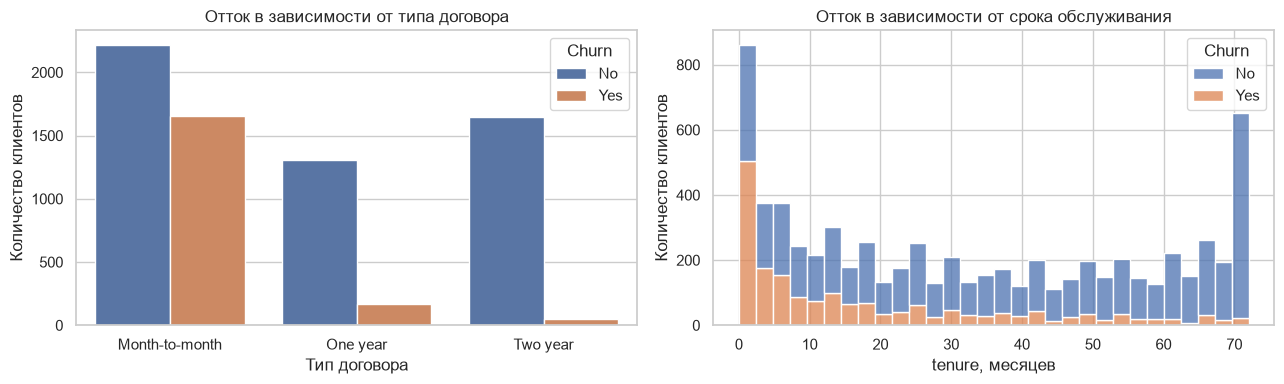

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.countplot(data=df, x='Contract', hue='Churn', ax=axes[0])
axes[0].set_title('Отток в зависимости от типа договора')
axes[0].set_xlabel('Тип договора')
axes[0].set_ylabel('Количество клиентов')

sns.histplot(data=df, x='tenure', hue='Churn', bins=30, multiple='stack', ax=axes[1])
axes[1].set_title('Отток в зависимости от срока обслуживания')
axes[1].set_xlabel('tenure, месяцев')
axes[1].set_ylabel('Количество клиентов')

plt.tight_layout()
plt.savefig('images/eda_contract_tenure.png', dpi=150)
plt.show()

Видно, что уходят в основном клиенты с помесячным договором (Month-to-month) и те, кто пользуется услугами недавно (первые месяцы). Клиенты с договором на 2 года почти не уходят.

## Этап 2. Предобработка

### 5. Удаление customerID

In [11]:
df = df.drop(columns=['customerID'])
df.shape

(7043, 20)

### 6. Кодирование бинарных признаков

Бинарными считаю столбцы, у которых ровно два уникальных значения. `SeniorCitizen` уже закодирован как 0/1, его не трогаю.

In [12]:
binary_cols = [col for col in df.columns if df[col].nunique() == 2 and col != 'SeniorCitizen']
print('Бинарные признаки:', binary_cols)

for col in binary_cols:
    print(f'{col}: {df[col].unique().tolist()}')

Бинарные признаки: ['gender', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling', 'Churn']
gender: ['Female', 'Male']
Partner: ['Yes', 'No']
Dependents: ['No', 'Yes']
PhoneService: ['No', 'Yes']
PaperlessBilling: ['Yes', 'No']
Churn: ['No', 'Yes']


In [13]:
binary_map = {'Yes': 1, 'No': 0, 'Male': 1, 'Female': 0}

for col in binary_cols:
    df[col] = df[col].map(binary_map).astype(int)

df[binary_cols].head()

,gender,Partner,Dependents,PhoneService,PaperlessBilling,Churn
0,0,1,0,0,1,0
1,1,0,0,1,0,0
2,1,0,0,1,1,1
3,1,0,0,0,0,0
4,0,0,0,1,1,1


### 7. One-Hot Encoding категориальных признаков

Остались столбцы с тремя и более категориями: `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`, `Contract`, `PaymentMethod`. Порядка между значениями у них нет, поэтому использую One-Hot Encoding. Параметр `drop_first=True` убирает одну колонку из каждой группы, чтобы не было мультиколлинеарности (для логистической регрессии это полезно).

In [14]:
cat_cols = [col for col in df.columns if df[col].dtype not in ('int64', 'float64')]
print('Категориальные признаки:', cat_cols)

df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)
print('Размерность после One-Hot Encoding:', df_encoded.shape)
df_encoded.head()

Категориальные признаки: ['MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaymentMethod']
Размерность после One-Hot Encoding: (7043, 31)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,1,29.85,29.85,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0
1,1,0,0,0,34,1,0,56.95,1889.50,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,1
2,1,0,0,0,2,1,1,53.85,108.15,1,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1
3,1,0,0,0,45,0,0,42.30,1840.75,0,1,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,1,0,0,0,0
4,0,0,0,0,2,1,1,70.70,151.65,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0


## Этап 3. Моделирование

### 8. Признаки X и целевая переменная y

In [15]:
X = df_encoded.drop(columns=['Churn'])
y = df_encoded['Churn']

print('X:', X.shape)
print('y:', y.shape)

X: (7043, 30)
y: (7043,)


### 9. Разбиение на train (80%) и test (20%)

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print('Train:', X_train.shape, ' доля ушедших:', round(y_train.mean(), 3))
print('Test: ', X_test.shape, ' доля ушедших:', round(y_test.mean(), 3))

Train: (5634, 30)  доля ушедших: 0.265
Test:  (1409, 30)  доля ушедших: 0.265


### 10. Обучение логистической регрессии

Логистическая регрессия чувствительна к масштабу признаков: `TotalCharges` измеряется тысячами, а dummy-признаки — нулями и единицами. Поэтому масштабирую данные через `StandardScaler`. Важный момент: scaler обучаю **только на train**, а к test применяю уже обученный, чтобы информация из тестовой выборки не «утекла» в модель.

In [17]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

log_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
log_reg.fit(X_train_scaled, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

## Этап 4. Оценка

### 11. Предсказание на тестовой выборке

In [ ]:
y_pred_lr = log_reg.predict(X_test_scaled)
y_proba_lr = log_reg.predict_proba(X_test_scaled)[:, 1]  # вероятность класса 1 (ушёл)

print('Первые 10 предсказаний:', y_pred_lr[:10])
print('Первые 10 истинных:    ', y_test.values[:10])

Первые 10 предсказаний: [0 1 0 0 0 1 0 0 0 0]
Первые 10 истинных:     [0 0 0 0 0 0 0 0 0 1]


### 12. Classification report

In [19]:
print(classification_report(y_test, y_pred_lr, target_names=['Остался (0)', 'Ушёл (1)']))

              precision    recall  f1-score   support

 Остался (0)       0.85      0.89      0.87      1035
    Ушёл (1)       0.66      0.57      0.61       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409


### 13. Матрица ошибок

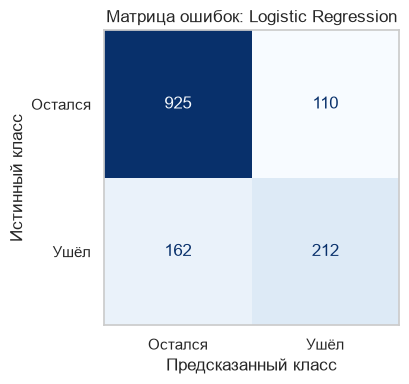

TN = 925, FP = 110, FN = 162, TP = 212


In [20]:
cm_lr = confusion_matrix(y_test, y_pred_lr)

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm_lr, display_labels=['Остался', 'Ушёл']).plot(cmap='Blues', ax=ax, colorbar=False)
ax.set_title('Матрица ошибок: Logistic Regression')
ax.set_xlabel('Предсказанный класс')
ax.set_ylabel('Истинный класс')
ax.grid(False)
plt.tight_layout()
plt.savefig('images/cm_logreg.png', dpi=150)
plt.show()

tn, fp, fn, tp = cm_lr.ravel()
print(f'TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}')

### 14. ROC-AUC

In [21]:
roc_auc_lr = roc_auc_score(y_test, y_proba_lr)
print(f'ROC-AUC (Logistic Regression): {roc_auc_lr:.4f}')

ROC-AUC (Logistic Regression): 0.8418


**Промежуточный вывод по логистической регрессии.** Accuracy 0.81, ROC-AUC 0.842 — для такой модели это нормальный результат: модель хорошо ранжирует клиентов по риску ухода. Слабое место — Recall по классу «Ушёл»: модель находит только 57% ушедших клиентов (212 из 374), а 162 ушедших пропускает (FN в матрице ошибок). Это прямое следствие дисбаланса классов.

## Задания со звёздочкой

### 1. Ансамбль: Random Forest

Деревьям масштабирование не нужно, поэтому обучаю Random Forest на исходных (немасштабированных) данных. Немного ограничил глубину деревьев и минимальный размер листа, чтобы лес не переобучался.

In [22]:
rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_leaf=5,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
y_proba_rf = rf.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_rf, target_names=['Остался (0)', 'Ушёл (1)']))
print(f'ROC-AUC (Random Forest): {roc_auc_score(y_test, y_proba_rf):.4f}')

              precision    recall  f1-score   support

 Остался (0)       0.84      0.91      0.87      1035
    Ушёл (1)       0.66      0.51      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409

ROC-AUC (Random Forest): 0.8446


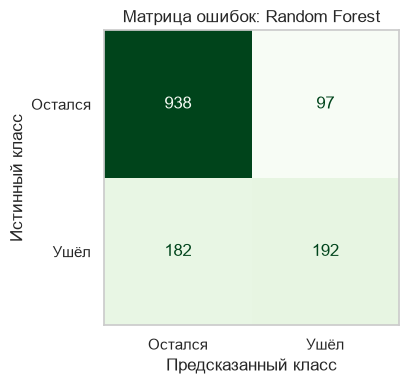

In [23]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_rf), display_labels=['Остался', 'Ушёл']).plot(
    cmap='Greens', ax=ax, colorbar=False)
ax.set_title('Матрица ошибок: Random Forest')
ax.set_xlabel('Предсказанный класс')
ax.set_ylabel('Истинный класс')
ax.grid(False)
plt.tight_layout()
plt.savefig('images/cm_rf.png', dpi=150)
plt.show()

Раз основная проблема — низкий Recall по ушедшим, сделаю ещё вариант леса с `class_weight='balanced'`. Этот параметр увеличивает «штраф» за ошибки на редком классе, и модель начинает чаще предсказывать уход.

In [24]:
rf_bal = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_leaf=5,
    class_weight='balanced',
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf_bal.fit(X_train, y_train)

y_pred_rf_bal = rf_bal.predict(X_test)
y_proba_rf_bal = rf_bal.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_rf_bal, target_names=['Остался (0)', 'Ушёл (1)']))
print(f'ROC-AUC (Random Forest, balanced): {roc_auc_score(y_test, y_proba_rf_bal):.4f}')

              precision    recall  f1-score   support

 Остался (0)       0.91      0.74      0.82      1035
    Ушёл (1)       0.52      0.79      0.63       374

    accuracy                           0.75      1409
   macro avg       0.72      0.77      0.72      1409
weighted avg       0.81      0.75      0.77      1409

ROC-AUC (Random Forest, balanced): 0.8435


### 2. Сравнение моделей

In [25]:
models = {
    'Logistic Regression': (y_pred_lr, y_proba_lr),
    'Random Forest': (y_pred_rf, y_proba_rf),
    'Random Forest (balanced)': (y_pred_rf_bal, y_proba_rf_bal),
}

rows = []
for name, (pred, proba) in models.items():
    report = classification_report(y_test, pred, output_dict=True)
    rows.append({
        'Модель': name,
        'Accuracy': report['accuracy'],
        'Precision (1)': report['1']['precision'],
        'Recall (1)': report['1']['recall'],
        'F1 (1)': f1_score(y_test, pred),
        'ROC-AUC': roc_auc_score(y_test, proba),
    })

comparison = pd.DataFrame(rows).set_index('Модель').round(4)
comparison

,Accuracy,Precision (1),Recall (1),F1 (1),ROC-AUC
Модель,,,,,
Logistic Regression,0.8070,0.6584,0.5668,0.6092,0.8418
Random Forest,0.8020,0.6644,0.5134,0.5792,0.8446
Random Forest (balanced),0.7537,0.5238,0.7941,0.6312,0.8435


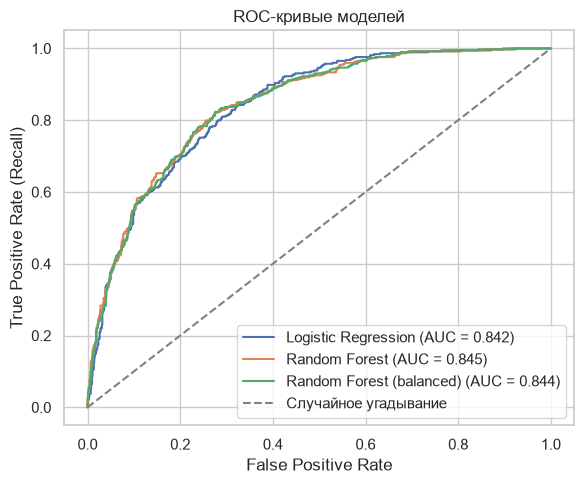

In [26]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, (pred, proba) in models.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc_score(y_test, proba):.3f})')
ax.plot([0, 1], [0, 1], linestyle='--', color='grey', label='Случайное угадывание')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate (Recall)')
ax.set_title('ROC-кривые моделей')
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig('images/roc_curves.png', dpi=150)
plt.show()

**Стало лучше?** Нет. Random Forest дал чуть более высокий ROC-AUC (0.845 против 0.842), но F1 по классу «ушёл» у него даже ниже (0.58 против 0.61), потому что он ещё осторожнее предсказывает уход и Recall падает до 0.51. Разница по ROC-AUC в третьем знаке — это шум, а не реальное улучшение.

Заметный выигрыш дала не смена модели, а учёт дисбаланса: Random Forest с `class_weight='balanced'` находит больше ушедших клиентов (Recall по классу 1 вырос с 0.57 у логистической регрессии до 0.79), и F1 по этому классу стал лучшим из трёх моделей — 0.63. ROC-AUC при этом не изменился: `class_weight` влияет в основном на то, где проходит порог решения, а не на то, как модель ранжирует клиентов. Цена такого решения — много ложных тревог (Precision ниже). Для задачи удержания клиентов такой компромисс обычно выгоден: позвонить лишний раз лояльному клиенту дешевле, чем потерять уходящего.

### ⭐ 3. Важность признаков

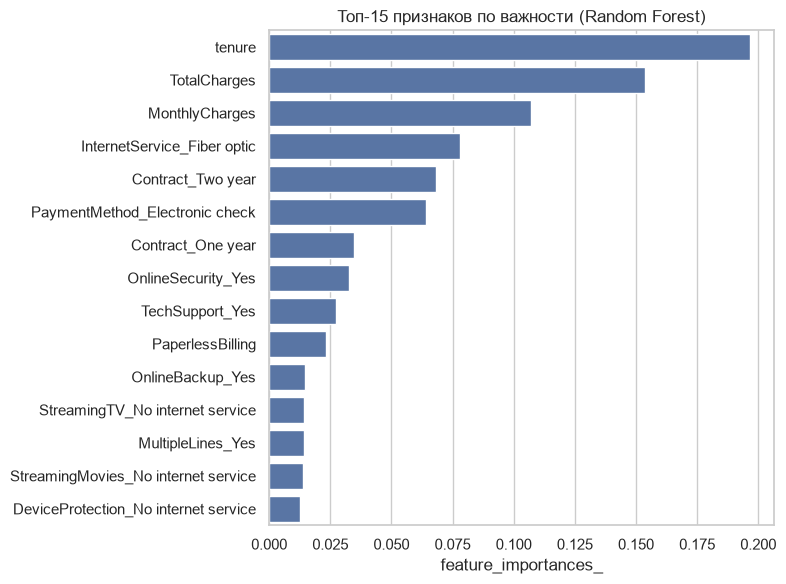

tenure                                  0.1966
TotalCharges                            0.1537
MonthlyCharges                          0.1072
InternetService_Fiber optic             0.0782
Contract_Two year                       0.0683
PaymentMethod_Electronic check          0.0641
Contract_One year                       0.0347
OnlineSecurity_Yes                      0.0328
TechSupport_Yes                         0.0272
PaperlessBilling                        0.0230
OnlineBackup_Yes                        0.0145
StreamingTV_No internet service         0.0144
MultipleLines_Yes                       0.0143
StreamingMovies_No internet service     0.0137
DeviceProtection_No internet service    0.0125
dtype: float64

In [27]:
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
top15 = importances.head(15)

fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(x=top15.values, y=top15.index, color='#4C72B0', ax=ax)
ax.set_title('Топ-15 признаков по важности (Random Forest)')
ax.set_xlabel('feature_importances_')
ax.set_ylabel('')
plt.tight_layout()
plt.savefig('images/feature_importances.png', dpi=150)
plt.show()

top15.round(4)

**Какой фактор главный?** По версии Random Forest главный признак — срок обслуживания `tenure` (≈0.20), а за ним идут `TotalCharges` и `MonthlyCharges`, потом оптоволоконный интернет (`InternetService_Fiber optic`), договор на 2 года (`Contract_Two year`) и оплата через `Electronic check`. Это совпадает графиками в EDA: уходят новые клиенты на помесячном договоре.

`feature_importances_` у случайного леса немного завышает важность непрерывных признаков (`tenure`, `TotalCharges`, `MonthlyCharges`), потому что по ним можно сделать больше разбиений. Поэтому для проверки можно посмотреть ещё и на коэффициенты логистической регрессии — данные масштабированы, так что их можно сравнивать между собой.

In [28]:
coefs = pd.Series(log_reg.coef_[0], index=X.columns)
top_coefs = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(10)
top_coefs.round(3)

tenure                        -1.237
MonthlyCharges                -0.920
InternetService_Fiber optic    0.776
Contract_Two year             -0.587
TotalCharges                   0.514
Contract_One year             -0.286
StreamingMovies_Yes            0.257
StreamingTV_Yes                0.257
MultipleLines_Yes              0.216
PaperlessBilling               0.182
dtype: float64

Логистическая регрессия тоже ставит на первое место `tenure` (с отрицательным знаком — чем дольше клиент с нами, тем меньше вероятность ухода). Большой положительный коэффициент у `InternetService_Fiber optic` и отрицательный у `Contract_Two year` тоже совпадают с выводами леса.

Итого: главный фактор оттока — **срок обслуживания клиента (`tenure`)**, а за ним — сумма платежей, тип интернета и тип договора.

## Итоги

1. Датасет содержит 7043 клиента и 21 признак. Единственная проблема в данных — 11 пустых строк в `TotalCharges` у новых клиентов (`tenure = 0`), их заполнил нулями и привёл столбец к `float64`.
2. Классы несбалансированы: ушедших около 26.5%.
3. Логистическая регрессия со `StandardScaler`: accuracy 0.81, F1 по классу «ушёл» 0.61, ROC-AUC 0.842.
4. Random Forest: ROC-AUC 0.845 (практически то же самое), F1 0.58 — ансамбль сам по себе лучше не стал. Заметное улучшение дал учёт дисбаланса: Random Forest с `class_weight='balanced'` — Recall 0.79, F1 0.63.
5. Главный фактор оттока — `tenure` (срок обслуживания). Также важны размер платежей, оптоволоконный интернет, тип договора и оплата электронным чеком.